In [1]:
import pandas as pd
import numpy as np

In [2]:
btc = pd.read_csv("../data_raw/btc.csv", usecols=["time", "PriceUSD"], parse_dates=["time"])
btc = btc.rename(columns={"time": "date", "PriceUSD": "price"}).set_index("date")
btc = btc.loc["2017-09-01":"2025-12-31"]
print(len(btc), btc.index.min(), btc.index.max(), btc["price"].isna().sum())

3044 2017-09-01 00:00:00 2025-12-31 00:00:00 0


In [3]:
btc["ret"] = btc["price"].pct_change()
r = btc.loc["2018":"2025", "ret"]
print(r.mean(), r.std(), r.min(), r.idxmin())

0.0012212869405938628 0.0341958520865199 -0.3753495151221997 2020-03-12 00:00:00


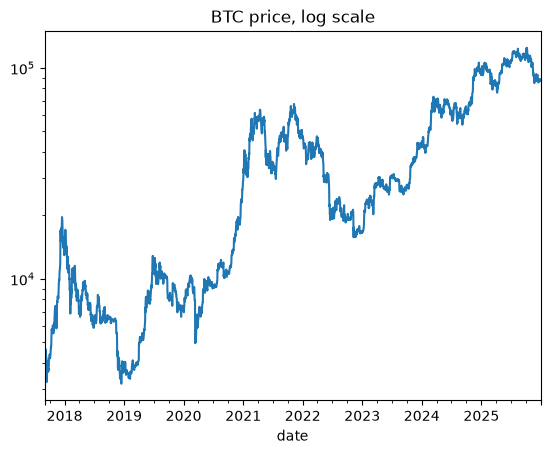

In [4]:
btc["price"].plot(logy=True, title="BTC price, log scale")
btc.to_csv("../data_clean/btc_clean.csv")